# Notebook 04: Shear-wave splitting, step by step: one earthquake at RCM

**Goal (about 2.5 hours):** measure shear-wave splitting on one earthquake yourself, with SWSPy, the way the research pipeline does it, in five steps:

1. **Data** (section 2): the earthquake from the catalog, its picks, its waveforms at the station.
2. **Pre-processing** (section 3): orient the components, trace the ray (PyKonal), check the P wave, choose the filter band, and apply the gates that decide whether a measurement is worth attempting.
3. **Analysis** (section 4): the splitting measurement with SWSPy, its diagnostic figure and the split itself.
4. **Post-processing** (section 5): the cuts that decide whether the measurement is trusted, and the percent anisotropy.
5. **Plot** (section 6): the measurement on the map.

The station is **RCM**, at Camp Muir on the volcano's south flank; the earthquake is event 62137112, a magnitude 1.0 on 9 July 2025, in the first days of the swarm. It passes every step with the stricter pre-processing gates this lesson uses, and the measurement made here reproduces the research pipeline's to the digit.

Section 1 sets out what is being measured. This lesson builds on notebooks 01 to 03 (seismograms, catalogs and maps, filtering and SNR). Words in **bold** are defined where they first appear; section 8 collects them in a glossary. The notebook runs in about a minute.

In [1]:
# --- setup: make the repo importable and keep figures inline ---
import sys
from pathlib import Path
REPO = Path.cwd().parent if (Path.cwd() / "../rainier_sws").exists() else Path.cwd()
sys.path.insert(0, str(REPO))
# --- check the kernel: these lessons are built for the rainier-sws environment (environment.yml) ---
import importlib.util
import numpy as np
_problems = [f"Python {sys.version.split()[0]} (expected 3.11)"] if sys.version_info[:2] != (3, 11) else []
_problems += [f"numpy {np.__version__} (expected < 2)"] if int(np.__version__.split(".")[0]) >= 2 else []
_problems += ["no PyKonal (section 3.2 needs it)"] if importlib.util.find_spec("pykonal") is None else []
if _problems:
    print("WARNING: this kernel is not the rainier-sws environment: " + "; ".join(_problems) + ".\n"
          "In the Anaconda Prompt run\n"
          "    conda activate rainier-sws\n"
          "    python -m ipykernel install --user --name rainier-sws --display-name \"rainier-sws (3.11)\"\n"
          "then choose that kernel (Kernel > Change Kernel) and run the notebook again.\n")
%matplotlib inline
import contextlib, io
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patheffects as pe
import obspy
from obspy.geodetics import gps2dist_azimuth
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
from swspy.splitting import split_windowcheck          # SWSPy (Hudson et al., 2023), the repo's copy
from rainier_sws import paths, data, measure, quality, stats, reference, plots, raytrace
from rainier_sws import sws_functions as swsf

STATION, NETWORK, EVID = "RCM", "UW", 62137112   # the station and the earthquake this lesson follows
PICKS = quality.PickQuality()                    # step 1: both picks of quality 0.75 or better
GATES = quality.SHEAR_WINDOW_PRE                 # step 2: this lesson's pre-processing gates
SWS = measure.SwsParams()                        # step 3: SWSPy's settings, as in the research pipeline
POST = quality.DEFAULT_POST                      # step 4: the post-processing filter
print(PICKS, GATES, SWS, POST, sep="\n")

PickQuality(p_min=0.75, s_min=0.75)
PreGates(clip_fraction_max=0.97, rectilinearity_min=0.7, incidence_max_deg=35.0, snr_min=2.0)
SwsParams(s_pick_uncertainty=0.03, first_window_start=2, last_window_start=1, first_window_end=1.5, last_window_end=2.5, n_win=7, max_t_shift_s=0.2, cluster_eps=0.15, cluster_min_samples=15, coord_system='LQT', sws_method='EV_and_XC')
PostFilter(snr_min=2.0, qw_min=0.75, dt_error_max=0.05, phi_error_max=20.0, dt_period_fraction=0.5)


## 1. What we are measuring

Shallow rock is full of cracks. Where they line up, the rock is **anisotropic**: its wave speed depends on direction. An S wave shaking the ground *parallel* to the cracks travels at the normal speed; one shaking *across* them makes their faces slide against each other and travels slightly slower. The direction in which a wave shakes the ground is its **polarization**.

An S wave that enters such rock with any other polarization splits in two: a **fast wave** polarized along the cracks and a **slow wave** polarized across them. At the station the slow one lags the fast one by **dt**, the delay time, and the fast one is polarized along **phi**, the fast direction, clockwise from north (an axis: phi and phi + 180 are the same). That is **shear-wave splitting**. The measurement turns a seismogram back into phi and dt.

**Stress or structure?** Two kinds of alignment compete, and telling them apart is the project's question (README). Under stress, cracks across the direction of **maximum horizontal compressive stress** are pressed shut and cracks along it stay open, so phi follows the stress; regionally it points about NE. Faults, old dikes and layered flows hold aligned fractures whatever the present stress, so phi can instead follow their strike; the 2009 swarm outlined a structure striking about NE (Shelly, Moran & Thelen, 2013) but additional structures activated in the 2025 swarm could follow historical radial dike structures or other subsurface fault features. Thus, differentiating which mechanism controls anistropy is key: regional stress, local geological structures, or both.

**How strong: percent anisotropy.** If the fast and slow speeds differ by a small fraction, a wave that travels for a time T_S picks up a delay dt of about that fraction times T_S. Dividing it out gives a property of the rock, the **percent anisotropy** A = 100 x dt / T_S, the percentage by which the slow wave is slower than the fast, averaged along the path: the project's measure of crack density. You can think of percent anisotropy as a percentage measure of how cracked the rock is, normlarized by **T_S**, the S travel time along the ray from the earthquake to the station derived from ray tracing (section 3.2).

## 2. Data

### 2.1 The earthquake, from the catalog

An earthquake **catalog** lists, for every earthquake a network located, its **origin time**, its **hypocenter** (latitude, longitude, depth; the point above it is the **epicenter**) and its **magnitude**. The Pacific Northwest Seismic Network (**PNSN**, network code UW) locates Rainier's earthquakes and sends each one to the USGS national catalog, **ComCat**, as "uw" + its event number (the **evid**). `data.fetch_comcat_events` asks ComCat's **FDSN** event service for the 2025 swarm (within 0.1 degrees of the summit, 8 July to 25 August); without a network connection the cell uses PNSN's own export in the repo. Depths are km below sea level.

1362 events from USGS ComCat (live)
event 62137112: 2025-07-09 20:12:29 UTC, M 1.04, 46.8483 N 121.7675 W, 0.90 km below sea level; 93% of the swarm's events are smaller


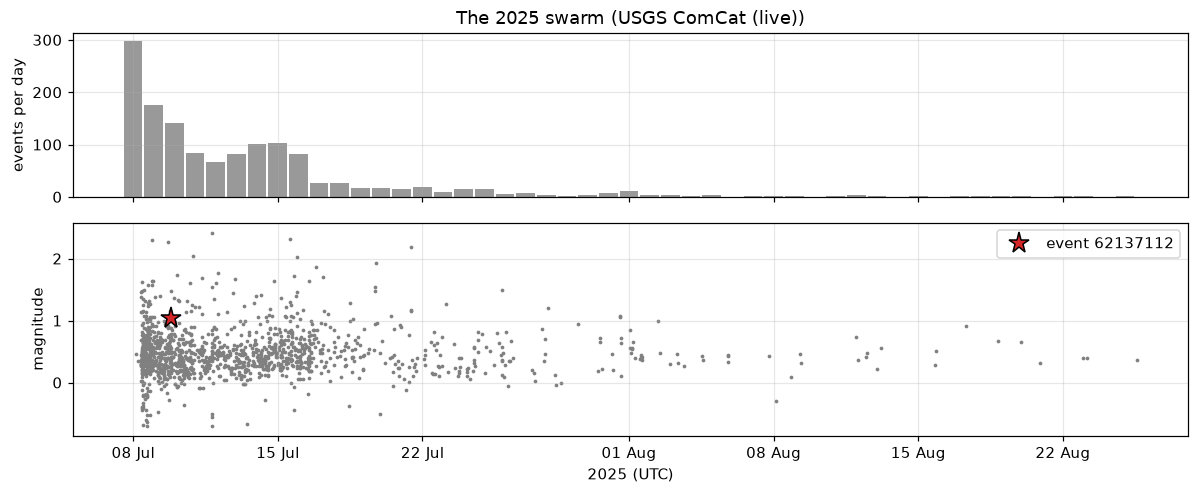

In [2]:
try:
    events = data.fetch_comcat_events()                      # live, a few seconds
    source = "USGS ComCat (live)"
except Exception as exc:                                      # offline: PNSN's export, in the repo
    events, source = data.load_events()[["evid", "time", "lat", "lon", "depth", "magnitude"]], f"repo copy ({type(exc).__name__})"
ev = events.set_index("evid").loc[EVID]
print(f"{len(events)} events from {source}")
print(f"event {EVID}: {ev.time:%Y-%m-%d %H:%M:%S} UTC, M {ev.magnitude:.2f}, {ev.lat:.4f} N {abs(ev.lon):.4f} W, "
      f"{ev.depth:.2f} km below sea level; {(events.magnitude < ev.magnitude).mean():.0%} of the swarm's events are smaller")

per_day = events.set_index("time").magnitude.resample("D").count()
fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
ax0.bar(per_day.index, per_day.values, width=0.9, color="0.6")
ax0.set(ylabel="events per day", title=f"The 2025 swarm ({source})")
ax1.scatter(events.time, events.magnitude, s=6, color="0.5", lw=0)
ax1.plot(ev.time, ev.magnitude, "*", color="tab:red", ms=14, mec="k", label=f"event {EVID}")
ax1.set(ylabel="magnitude", xlabel="2025 (UTC)"); ax1.legend(loc="upper right")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.tight_layout()

### 2.2 Its picks, and their quality

A **pick** is the time an analyst marks the arrival of P or S on one station's seismogram. PNSN grades every pick from 1 (sharp) down to 0.25; ComCat stores the grade as a time **uncertainty** (0.03 s for quality 1, 0.06 s for 0.75, 0.15 s for 0.5, 0.3 s for 0.25; `data.PNSN_QUALITY_FROM_UNCERTAINTY`). `data.load_event_picks` reads the event's picks from ComCat's phase-data file (**QuakeML**, the XML format for earthquakes and picks), downloading it if the repo does not have it. The pipeline keeps an earthquake-station pair only if both its P and S picks have quality 0.75 or better (`quality.PickQuality`): the S pick places the analysis windows (section 4), the P pick the P-wave check (section 3.3).

In [3]:
picks = data.load_event_picks(EVID)                          # data/catalog/quakeml/uw62137112.xml
print(f"{len(picks)} picks at {picks.station.nunique()} stations")
print(picks[picks.station.isin([STATION, "STAR", "MILD"])][["station", "channel", "phase", "time", "uncertainty", "quality", "distance_km"]]
      .round(3).to_string(index=False))
cat = data.load_station_catalog(STATION)                     # RCM's pairs with a P and an S pick (both quality >= 0.5)
row = cat.set_index("evid").loc[EVID].copy(); row["evid"] = EVID
passes = EVID in set(cat[quality.pick_quality_mask(cat, PICKS)].evid)
print(f"\nat RCM: P quality {row.p_quality}, S quality {row.s_quality}: passes the pick-quality filter: {passes} "
      f"(as do {quality.pick_quality_mask(cat, PICKS).sum()} of RCM's {len(cat)} pairs)")
origin, p_time, s_time = data.to_utc(row.origin_time), data.to_utc(row.p_time), data.to_utc(row.s_time)
print(f"S - P at RCM: {s_time - p_time:.2f} s")

29 picks at 20 stations
station channel phase                        time  uncertainty  quality  distance_km
   STAR     EHZ     P 2025-07-09T20:12:30.370000Z         0.03     1.00        1.963
   STAR     ELZ     S 2025-07-09T20:12:31.000000Z         0.06     0.75        1.963
    RCM     HHZ     P 2025-07-09T20:12:30.380000Z         0.03     1.00        2.989
    RCM     HHN     S 2025-07-09T20:12:31.050000Z         0.06     0.75        2.989
   MILD     BHZ     P 2025-07-09T20:12:30.540000Z         0.03     1.00        4.519

at RCM: P quality 1.0, S quality 0.75: passes the pick-quality filter: True (as do 509 of RCM's 856 pairs)
S - P at RCM: 0.67 s


RCM's P pick has quality 1 and its S pick 0.75, so the pair enters. S picks are usually less certain than P picks: S arrives in the middle of the P wave's tail, not out of quiet ground. The **S-P time**, 0.67 s, grows with distance.

### 2.3 Its waveforms at RCM

RCM sits at 3077 m, 2.8 km south-east of the summit, with a **broadband** seismometer (channels `HH?`, 100 samples per second). The waveforms are fetched from EarthScope once, for the research pipeline's window (5 s before the origin to 15 s after), and kept in the repo as miniSEED; the amplitudes are raw **counts**. Splitting compares the components with each other, so no instrument correction is needed.

3 Trace(s) in Stream:
UW.RCM..HHZ | 2025-07-09T20:12:24.600000Z - 2025-07-09T20:12:44.590000Z | 100.0 Hz, 2000 samples
UW.RCM..HHN | 2025-07-09T20:12:24.600000Z - 2025-07-09T20:12:44.590000Z | 100.0 Hz, 2000 samples
UW.RCM..HHE | 2025-07-09T20:12:24.600000Z - 2025-07-09T20:12:44.590000Z | 100.0 Hz, 2000 samples


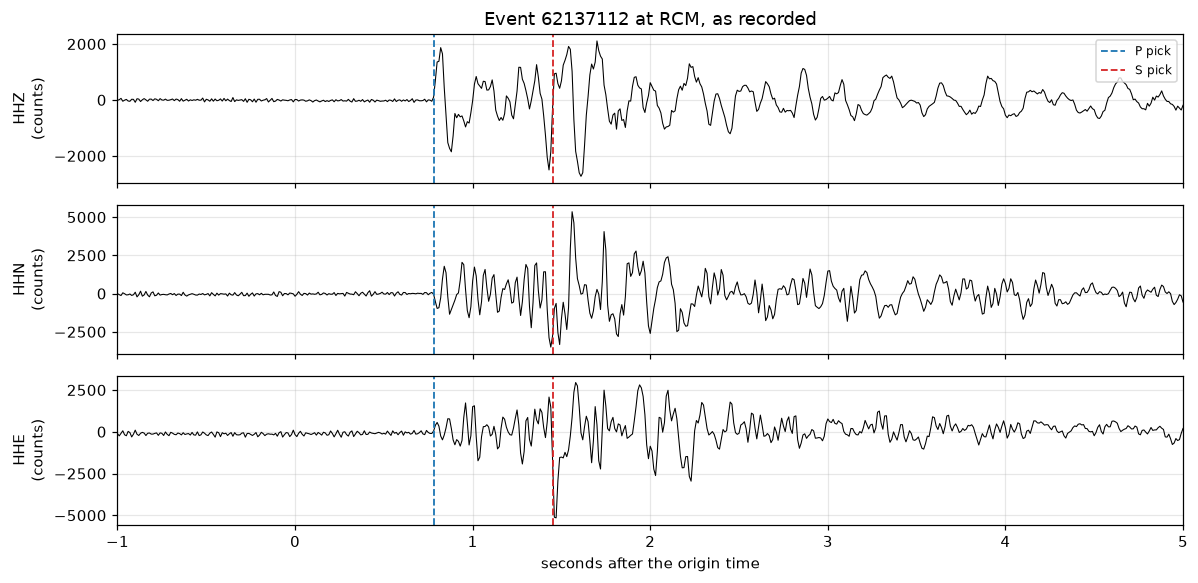

In [4]:
wave_file = paths.WAVEFORMS / "notebook04" / f"{NETWORK}.{STATION}.{EVID}.mseed"
if not wave_file.exists():                                   # fetch once from EarthScope (notebook 02)
    t0 = data.to_utc(row.start_time)
    data.fetch_from_earthscope(NETWORK, STATION, t0, t0 + data.PRE_S + data.POST_S).write(str(wave_file), format="MSEED")
st_raw = obspy.read(str(wave_file))
print(st_raw)
fig, axes = plt.subplots(3, 1, figsize=(11, 5.4), sharex=True)
for ax, c in zip(axes, "ZNE"):
    tr = st_raw.select(channel=f"??{c}")[0]
    ax.plot(tr.times(reftime=origin), tr.data - tr.data.mean(), "k", lw=0.7)
    ax.axvline(p_time - origin, color="tab:blue", ls="--", lw=1.2, label="P pick")
    ax.axvline(s_time - origin, color="tab:red", ls="--", lw=1.2, label="S pick")
    ax.set_ylabel(f"{tr.stats.channel}\n(counts)")
axes[0].legend(loc="upper right", fontsize=8)
axes[0].set_title(f"Event {EVID} at {STATION}, as recorded")
axes[-1].set(xlim=(-1, 5), xlabel="seconds after the origin time")
plt.tight_layout()

The P wave arrives on all three components 0.78 s after the origin; the S wave follows 0.67 s later, about twice as large and largest on the horizontals, near 5,000 counts.

## 3. Pre-processing

### 3.1 Orientation and geometry

The components must point where their names say: Z up, N north, E east. `data.orient_zne` rotates them to true Z, N, E from the archived metadata and any known corrections (README: STAR's are exchanged); RCM's are nominal for July 2025, so they come back unchanged. The **back azimuth** is the direction from the station to the earthquake, clockwise from north.

In [ ]:
st = data.orient_zne(st_raw)                                  # true Z, N, E
sta_lat, sta_lon, sta_elev = data.station_coords(STATION)
print("archived orientation (azimuth, dip, source):", {tr.stats.channel: data.channel_orientation(tr) for tr in st_raw})
print("unchanged by the orientation step:", all((st.select(channel=f"??{c}")[0].data == st_raw.select(channel=f"??{c}")[0].data).all() for c in "ZNE"))
back_azimuth = swsf.calculate_back_azimuth(row.event_lat, row.event_lon, sta_lat, sta_lon)
epi_km = gps2dist_azimuth(sta_lat, sta_lon, row.event_lat, row.event_lon)[0] / 1000
below_km = row.event_depth + sta_elev / 1000                   # catalog depth (below sea level) + RCM's elevation
print(f"back azimuth {back_azimuth:.2f} deg; epicentral distance {epi_km:.2f} km; {below_km:.2f} km below RCM")

relief, extent = plots.shaded_relief()
sta = data.load_stations().set_index("station")
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(relief, extent=extent, zorder=0)
ax.scatter(events.lon, events.lat, s=4, c="k", alpha=0.3, lw=0, label="the swarm")
ax.plot([sta_lon, row.event_lon], [sta_lat, row.event_lat], color="tab:red", lw=1.5, ls="--", label="back azimuth")
ax.plot(row.event_lon, row.event_lat, "*", color="white", mec="k", ms=15, zorder=6, label=f"event {EVID}")
ax.plot(*plots.SUMMIT[::-1], "^", color="#C04000", mec="k", ms=12, label="summit")
ax.plot(sta_lon, sta_lat, "^", color="#FFD700", mec="k", ms=12, label=STATION)
ax.annotate(STATION, (sta_lon, sta_lat), xytext=(8, -12), textcoords="offset points", weight="bold",
            path_effects=[pe.withStroke(linewidth=3, foreground="w")])
ax.set(xlim=plots.MAP_LON_RANGE, ylim=plots.MAP_LAT_RANGE,       # centred on the summit, as in section 6
       aspect=1 / np.cos(np.deg2rad(plots.SUMMIT[0])),
       xlabel="longitude", ylabel="latitude", title="The earthquake seen from RCM")
ax.grid(False); ax.ticklabel_format(useOffset=False); ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()

The earthquake is 2.98 km north-west of RCM (back azimuth 298.5 degrees), 0.9 km below sea level and 3.98 km below the station.

### 3.2 The ray: PyKonal

Rock gets faster with depth, so rays bend towards the vertical as they climb, and both the angle at which the S wave reaches the station and its travel time depend on the velocity model. The pipeline computes them by **ray tracing** with the Python package **PyKonal** (White et al., 2020). PyKonal solves the **eikonal equation** (the equation for the first-arrival travel time through a velocity model) on a 3-D grid by the fast-marching method. The travel-time field at the hypocenter is T_S; following its gradient back to the station gives the ray, and the ray's last segment gives the **incidence angle**, the angle from vertical at which it arrives. The model is the research pipeline's S-wave model of the summit (Vs = iMUSH Vp / 1.73, Ulberg et al., 2020, on a 1.2 km grid; `rainier_sws.raytrace`).

The incidence angle is a gate. Beyond the **critical angle**, arcsin(Vs / Vp) = 35.3 degrees for Vp / Vs = 1.73, the ground surface itself distorts an arriving S wave in a way that looks like splitting, or generates secondary P_S or S_P converted phases. Only rays inside that near-vertical cone are measured. This lesson's gate is 35 degrees.

In [ ]:
from scipy.interpolate import RegularGridInterpolator
tracer = raytrace.StationRayTracer()                         # the cropped Rainier Vs model
tracer.precompute_station(STATION, sta_lat, sta_lon, sta_elev)   # the eikonal field from RCM (well under a second)
ray = tracer.trace(STATION, row.event_lat, row.event_lon, row.event_depth)
inc, T_S = ray["incidence_deg"], ray["travel_time_s"]
r_ = ray["ray"]                                                                      # x, y, z (km) from the earthquake to RCM's node
node = tracer.station_xyz(STATION)
true_xy = raytrace.ll2xy(sta_lat, sta_lon)
i_sta = 0 if np.linalg.norm(r_[0] - node) < np.linalg.norm(r_[-1] - node) else -1  # the ray's end at RCM
sta3, ev3 = r_[i_sta], r_[-1 - i_sta]
straight = np.degrees(np.arctan2(np.hypot(*(ev3[:2] - sta3[:2])), ev3[2] - sta3[2]))
print(f"T_S = {T_S:.3f} s; incidence angle {inc:.2f} deg (a straight line would arrive at {straight:.1f}); gate <= {GATES.incidence_max_deg:.0f}")
print(f"RCM sits on the grid node {np.hypot(node[0] - true_xy[0], node[1] - true_xy[1]):.2f} km from its position and "
      f"{node[2] + sta_elev / 1000:.2f} km below its elevation")

u = (ev3[:2] - sta3[:2]) / np.hypot(*(ev3[:2] - sta3[:2]))                          # from RCM towards the earthquake
ray_along, ray_below = (r_[:, :2] - sta3[:2]) @ u, r_[:, 2] - sta3[2]                # km along that direction, km below RCM
ev_along, ev_below = (ev3[:2] - sta3[:2]) @ u, ev3[2] - sta3[2]
gate, d = GATES.incidence_max_deg, 6                                                 # draw the gate 6 km down
# the model's Vs on the same vertical section: the plane through RCM's node and the earthquake
along, below = np.linspace(-4, 4.5, 171), np.linspace(-0.4, 5, 109)
S_, D_ = np.meshgrid(along, below)
vs_section = RegularGridInterpolator((tracer.x, tracer.y, tracer.z), tracer.vs)(
    np.column_stack([(sta3[0] + S_ * u[0]).ravel(), (sta3[1] + S_ * u[1]).ravel(), (sta3[2] + D_).ravel()])).reshape(S_.shape)
vs_at = lambda xyz: float(RegularGridInterpolator((tracer.x, tracer.y, tracer.z), tracer.vs)(xyz)[0])
print(f"Vs in the model: {vs_at(sta3):.2f} km/s at RCM's node, {vs_at(ev3):.2f} km/s at the earthquake")

fig, (ax, ax_v) = plt.subplots(1, 2, figsize=(13.5, 5.2), sharey=True, gridspec_kw={"width_ratios": [1, 1.18]})
ax.fill([0, -d * np.tan(np.deg2rad(gate)), d * np.tan(np.deg2rad(gate))], [0, d, d], color="tab:red", alpha=0.12, lw=0)
for s in (-1, 1):
    ax.plot([0, s * d * np.tan(np.deg2rad(gate))], [0, d], color="tab:red", ls="--", lw=1.2,
            label=f"gate: {gate:.0f} deg either side of vertical" if s == 1 else None)
ax.plot(ray_along, ray_below, "o-", color="tab:blue", lw=2, ms=3, label=f"PyKonal ray, arrives at {inc:.1f} deg")
ax.plot([0, ev_along], [0, ev_below], color="0.3", ls=":", label=f"straight line, would arrive at {straight:.1f} deg")
ax.plot(ev_along, ev_below, "*", color="tab:red", mec="k", ms=15, label=f"event {EVID}")
ax.plot(0, 0, "v", color="#FFD700", mec="k", ms=12, clip_on=False, zorder=5); ax.text(0.1, -0.15, STATION, weight="bold")
ax.set(xlim=(-4, 4.5), ylim=(5, -0.4), aspect="equal", xlabel="km from RCM towards the earthquake", ylabel="km below RCM",
       title="The S ray from the earthquake to RCM")
ax.legend(loc="lower left", fontsize=8)
mesh = ax_v.pcolormesh(along, below, vs_section, cmap="viridis_r", shading="auto")
ax_v.plot(ray_along, ray_below, "-", color="w", lw=2.2, path_effects=[pe.withStroke(linewidth=3.8, foreground="k")], label="PyKonal ray")
ax_v.plot(ev_along, ev_below, "*", color="tab:red", mec="k", ms=15)
ax_v.plot(0, 0, "v", color="#FFD700", mec="k", ms=12, clip_on=False, zorder=5)
ax_v.text(0.1, -0.15, STATION, weight="bold")
ax_v.set(xlim=(-4, 4.5), aspect="equal", xlabel="km from RCM towards the earthquake", title="The S-wave velocity model on the same section")
ax_v.grid(False); ax_v.legend(loc="lower left", fontsize=8)
fig.colorbar(mesh, ax=ax_v, label="Vs (km/s)", shrink=0.8, pad=0.02)
plt.tight_layout()

PyKonal's ray climbs from the earthquake and bends towards the vertical in the slower rock near the surface, arriving 32.2 degrees from vertical, inside the window and the 35-degree gate (the shaded wedge); a straight line from the earthquake would arrive at 42.4 and fail. The right panel shows why it bends: a depth cross-section of the velocity model along the same vertical plane (the model's Vs, interpolated between its nodes), in which Vs falls from 3.43 km/s at the earthquake to 2.78 km/s at RCM. T_S is 1.760 s. Both depend on the model: on its velocities, and on its 1.2 km grid, on which RCM is represented by the nearest node, 0.6 km from its position and 0.5 km below its elevation. The ray ends at that node and its angle is measured there, so the figure is drawn from the node: RCM is placed on it, and the earthquake appears 3.5 km below RCM rather than the 4.0 km printed above. Ideally, a finer resolution velocity model would give better constraints on the ray. Some of our collaborators at Rice University are working on this!

### 3.3 The P wave: particle motion, the ray frame and rectilinearity

The **particle motion** of a wave is the path a point on the ground traces as the wave passes, seen by plotting one component against another. Each body wave has its own, set by the ray it travels along: a **P** wave shakes the ground *along* the ray; an **SV** wave shakes it *across* the ray, in the vertical plane that holds the ray; an **SH** wave shakes it across the ray and horizontally. An earthquake's S wave is in general a mixture of SV and SH, so its polarization lies somewhere in the plane perpendicular to the ray, and that plane is where splitting happens.

![Particle motion of P, SV and SH waves](images/p_sv_sh_particle_motion.png)

*Particle displacement (double arrows) of P, SV and SH waves travelling along the same ray (black arrows) to a target at the surface: along the ray for P, across it in the vertical plane for SV, across it and horizontal for SH. Source: The University of Texas at Austin.*

The seismometer records in its own frame, Z, N, E, which knows nothing about the ray. The frame of the wave is the ray's, **LQT**: **L** along the ray, positive in the direction of travel (up, and away from the earthquake); **Q** perpendicular to it in the vertical plane through earthquake and station; **T** (transverse), horizontal and perpendicular to both. So L is the direction of P, Q of SV and T of SH. Rotating Z, N, E into L, Q, T takes the two angles already in hand, the back azimuth (section 3.1) and the incidence angle (section 3.2); in ObsPy it is `Stream.rotate("ZNE->LQT", back_azimuth, inclination)`. SWSPy makes the same rotation before it measures anything and searches for the split in the Q-T plane, the plane across the ray (section 4, where the rotated traces are plotted).

**Rectilinearity.** Because a P wave shakes the ground along its ray, its particle motion should be close to a straight line; if it is not, something is wrong with the station, the pick or the ray. The pipeline measures this in a short window around the P pick (0.02 s before to 0.10 s after) on the raw traces (Jurkevics, 1988). The three components' **covariance matrix** (how much each pair of components varies together) has eigenvalues lambda1 >= lambda2 >= lambda3, the squared lengths of the three axes of the ellipsoid the motion fills, and the **rectilinearity** 1 - (lambda2 + lambda3) / (2 lambda1) is 1 for motion along a line and 0 for motion spread evenly in every direction. The eigenvector of lambda1 is the direction of the P motion; its angle from vertical, the pipeline's `incidence_angle_jurkevics`, is compared with the ray-traced angle in notebook 05.

In [ ]:
p_off = p_time - st[0].stats.starttime
z, n, e = (st.select(channel=f"??{c}")[0] for c in "ZNE")
rect = float(np.real(swsf.calculate_rectilinearity_jurkevics(z, n, e, p_off)))
print(f"rectilinearity {rect:.3f}; gate >= {GATES.rectilinearity_min}")

### 3.4 The filter band and the S wave's SNR

The pipeline tries 14 bandpass filters (the **filter bank**, after MFAST; Savage et al., 2010) and keeps the one in which the S wave's **SNR** is highest: the mean amplitude in a short window after the S pick over that in the window before it, which here is the **P coda**, the tail of the P wave (notebook 03). It also measures the filtered S wave's **dominant period**, the length of one swing; half of it is the longest delay the pipeline will believe (the **cycle-skip** limit, section 5).

In [ ]:
band, st_filt, snr, dom_samples, snr_by_band = swsf.try_filters(obspy.Stream([z, n, e]), p_time, s_time)
print(f"best band {band[0]:g}-{band[1]:g} Hz, SNR {snr:.2f} (gate >= {GATES.snr_min}); dominant period {dom_samples / st[0].stats.sampling_rate:.3f} s")
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 1.5]})
ax0.barh([f"{a:g}-{b:g}" for a, b in snr_by_band], list(snr_by_band.values()),
         color=["tab:red" if k == band else "0.6" for k in snr_by_band])
ax0.axvline(GATES.snr_min, color="k", ls="--", lw=1)
ax0.set(xlabel="S-wave SNR", ylabel="band (Hz)", title="The filter bank"); ax0.invert_yaxis()
for c, col in [("N", "k"), ("E", "0.55")]:
    tr = st_filt.select(channel=f"??{c}")[0]
    ax1.plot(tr.times(reftime=s_time), tr.data, color=col, lw=1.1, label=f"HH{c}")
ax1.axvline(0, color="tab:red", ls="--", lw=1.2, label="S pick"); ax1.axvline(p_time - s_time, color="tab:blue", ls="--", lw=1.2, label="P pick")
ax1.set(xlim=(-1, 1.5), xlabel="seconds after the S pick", ylabel="counts (filtered)", title=f"The horizontals, {band[0]:g}-{band[1]:g} Hz")
ax1.legend(fontsize=8, loc="upper right")
plt.tight_layout()

The 3-5 Hz band wins, with an SNR of 8.8; 1-5 Hz comes a close second. The filtered S wave has a dominant period of 0.19 s.

### 3.5 The gates

The pipeline attempts a measurement only if the event passes every pre-processing gate (`quality.PreGates`, checked in this order; a station with a known clip level is also checked for clipping, which RCM does not have). This lesson's gates are stricter than the research pipeline's (`quality.SHEAR_WINDOW_PRE` against `quality.DEFAULT_PRE`, used by the results files and notebooks 05 to 07):

In [ ]:
gate_table = pd.DataFrame([("rectilinearity", rect, ">=", GATES.rectilinearity_min, quality.DEFAULT_PRE.rectilinearity_min),
                           ("incidence angle (deg)", inc, "<=", GATES.incidence_max_deg, quality.DEFAULT_PRE.incidence_max_deg),
                           ("S-wave SNR", snr, ">=", GATES.snr_min, quality.DEFAULT_PRE.snr_min)],
                          columns=["gate", "value", "rule", "this lesson", "research pipeline"]).set_index("gate")
gate_table["margin"] = np.where(gate_table.rule == ">=", gate_table.value - gate_table["this lesson"], gate_table["this lesson"] - gate_table.value)
gate_table["passes"] = gate_table.margin >= 0
gate_table.round(3)

It passes all three, two of them narrowly: rectilinearity 0.735 against 0.7, and an incidence angle 2.8 degrees inside the gate.

## 4. Analysis: the splitting measurement with SWSPy

SWSPy (Hudson, Asplet & Walker, 2023; the repo carries the research project's copy) measures splitting in two calls. `create_splitting_object` takes the filtered three-component stream and the geometry and sets up the **analysis windows**, the stretches of trace around the S pick it will measure in. `perform_sws_analysis` then does the measurement:

1. It rotates Z, N, E into the **ray frame**, **LQT** (section 3.3): **L** along the ray (from the back azimuth and the incidence angle), **Q** perpendicular to it in the vertical plane through earthquake and station, **T** perpendicular to both and horizontal. The S wave lies in the Q-T plane, and phi is searched there, as **phi from Q**; adding the back azimuth gives phi from north.
2. In each window it runs a **grid search**: for every trial phi (from -90 to 88 degrees in 2-degree steps) and dt (up to `max_t_shift_s`), it rotates Q and T into a trial fast and slow direction, shifts the slow wave earlier by dt, and measures how close to a straight line the corrected motion is, with **lambda2 / lambda1**, the smaller over the larger eigenvalue of the two components' covariance matrix (0 for a line: the **eigenvalue method**, Silver & Chan, 1991). The trial with the smallest value is the answer, and the set of trials that fit almost as well (by an **F-test**) gives the **formal errors** on phi and dt. All the trials together are the **misfit surface**.
3. It repeats this in 49 windows (7 starts from twice to once the S-pick uncertainty before the pick, 7 ends from 1.5 to 2.5 dominant periods after it), groups the 49 answers with **DBSCAN** (a clustering method that joins answers lying close together), and keeps the tightest cluster and, in it, the window with the smallest errors (Teanby et al., 2004).
4. It measures the split a second way, with the **cross-correlation method** (the trial at which the corrected fast and slow waves look most alike), and compares the two with the quality factor **Q_w** (Wüstefeld et al., 2010): near +1 when they agree as good splits do, near -1 for a null (section 5).
5. It estimates the **source polarization**, the direction the S wave shook before it was split.

The settings are the research pipeline's (`measure.SwsParams`). SWSPy prints a log as it works; the cell keeps it out of the way.

In [ ]:
def run_swspy(stream_filtered, back_azimuth, incidence, s_time, origin, params=SWS):
    """The two SWSPy calls of the research pipeline (run_sws_generic.py) for one station."""
    with contextlib.redirect_stdout(io.StringIO()):          # SWSPy's log
        so = split_windowcheck.create_splitting_object(
            stream_filtered, stations_in=[STATION], back_azis_all_stations=[back_azimuth],
            receiver_inc_angles_all_stations=[incidence], S_phase_arrival_times=[s_time], origin_times=[origin],
            first_window_start=params.first_window_start, last_window_start=params.last_window_start,
            first_window_end=params.first_window_end, last_window_end=params.last_window_end,
            n_win=params.n_win, s_pick_uncertainty=params.s_pick_uncertainty, max_t_shift_s=params.max_t_shift_s)
        so.perform_sws_analysis(coord_system=params.coord_system, sws_method=params.sws_method,
                                cluster_eps=params.cluster_eps, cluster_min_samples=params.cluster_min_samples)
    return so

so = run_swspy(st_filt, back_azimuth, inc, s_time, origin)
result = so.sws_result_df.iloc[0]
result[["phi_from_Q", "phi_from_N", "phi_err", "dt", "dt_err", "Q_w", "src_pol_from_N", "src_pol_from_N_err"]]

SWSPy found phi = 46 degrees from Q; adding the back azimuth (298.5) gives 344.5, the same axis as **164.5 degrees from north** (NNW-SSE). dt = 0.04 s, with formal errors of 18 degrees and 0.01 s; Q_w is 0.87; the source polarization is 40 degrees from north. Below, the numbers are collected in one record (`measure.Measurement`, the row the pipeline writes for each event), and checked against the research pipeline's row for this event.

In [ ]:
m = measure.Measurement(evid=EVID, station=STATION, back_azimuth=back_azimuth, rectilinearity=rect, incidence_angle=inc,
                        snr_horizontal=snr, filter_band=band, phi=float(result.phi_from_N), dt=float(result["dt"]),
                        phi_error=float(result.phi_err), dt_error=float(result.dt_err), quality=float(result.Q_w),
                        dominant_period=float(so.Tmid), src_pol=float(result.src_pol_from_N),
                        src_pol_error=float(result.src_pol_from_N_err), success=True, splitting_object=so, stream_filtered=st_filt)
ref = pd.read_csv(paths.station_results_csv(STATION)).set_index("evid").loc[EVID]       # the research pipeline's row
print("the same as the research pipeline:", {c: bool(np.isclose(getattr(m, c), ref[c])) for c in ["phi", "dt", "phi_error", "dt_error", "quality"]})
print(f"{len(so.clustering_info[STATION]['clusters_dict'])} cluster; "
      f"{sum(len(c['phis']) for c in so.clustering_info[STATION]['clusters_dict'].values())} of 49 windows in it; "
      f"dominant period {so.Tmid:.3f} s")

The measurement reproduces the research pipeline's exactly. 31 of the 49 windows agree in one cluster.

`plots.diagnostic_figure` draws the whole measurement on one page, in the layout of the axial-sws methods figures:

In [ ]:
fig = plots.diagnostic_figure(m, row, title=f"RCM: Shear-Wave Splitting Event {EVID} (9 July 2025, M {row.event_magnitude:.2f})",
                              depth_km=row.event_depth)

| panel | what it shows | for this event |
| --- | --- | --- |
| A | the filtered Z, N, E traces, the P and S picks, the 7 window starts (solid grey) and 7 ends (dashed) | the starts just before the S pick, the ends 0.29 to 0.47 s after it |
| B | the misfit surface (lambda2 / lambda1) of the best window, light = good fit; T_dom / 2 dashed; SWSPy's answer with its formal errors | one wide pale basin around 46 degrees from Q and 0.04 s, short of the cycle-skip line: many trials fit almost as well, hence the 18-degree error |
| C | the particle motion across the ray (Q against T) in the window, as recorded | a loop: the fast and slow waves no longer rise and fall together |
| D | the same with the split removed | a narrow band: the loop turned back into motion along the source polarization |
| E | every window's answer, with its errors, grouped by DBSCAN; the chosen one starred | one cluster |
| F, G | phi and dt of each window in the winning cluster | phi 42 to 52 degrees from Q, dt 0.04 s in every window |
| footer | the gate values, Q_w, and phi converted from Q to north | |

A **particle motion** plot (C, D) draws one component against another: the path the ground traces. An unsplit S wave moves along a line (**linear** particle motion); a split one traces a loop; removing the right split turns the loop back into a line. That is the whole measurement in one picture.

SWSPy measured in the ray frame of section 3.3. Rotated into it, the filtered traces show what it saw: the S wave on Q and T, the P wave mostly on L.

In [ ]:
lqt = st_filt.copy().rotate("ZNE->LQT", back_azimuth=back_azimuth, inclination=inc)
fig, axes = plt.subplots(3, 1, figsize=(11, 5), sharex=True, sharey=True)
for ax, c in zip(axes, "LQT"):
    tr = lqt.select(channel=f"??{c}")[0]
    ax.plot(tr.times(reftime=origin), tr.data, "k", lw=0.9)
    ax.axvline(p_time - origin, color="tab:blue", ls="--", lw=1.2); ax.axvline(s_time - origin, color="tab:red", ls="--", lw=1.2)
    ax.set_ylabel(f"{c}\n(counts)")
    if c in "QT":                                            # the shift between the fast and slow waves
        ax.axvspan(1.50, 1.54, color="red", alpha=0.3, lw=0)        # the full height of the panel
        ax.axvline(1.50 if c == "T" else 1.54, color="k", ls="--", lw=1.2)   # the box's start on T, its end on Q
        ax.text(1.55, 0.95, "δt", color="k", weight="bold", ha="left", va="top", transform=ax.get_xaxis_transform())
axes[0].legend(handles=[plt.Line2D([], [], color="tab:blue", ls="--", lw=1.2, label="P-wave pick"),
                        plt.Line2D([], [], color="tab:red", ls="--", lw=1.2, label="S-wave pick"),
                        plt.Rectangle((0, 0), 1, 1, color="red", alpha=0.3, lw=0, label="δt: the offset between wavelets - what gets measured")],
               loc="upper left", fontsize=8)
axes[0].set_title(f"Filtered {band[0]:g}-{band[1]:g} Hz, in the ray frame (back azimuth {back_azimuth:.1f}, incidence {inc:.1f} deg)")
axes[-1].set(xlim=(0.4, 2.6), xlabel="seconds after the origin time")
plt.tight_layout()

Splitting happens on the filtered waveform in the LQT frame. The light red box on Q and T, from 1.50 to 1.54 s after the origin, marks **δt** (dt, 0.04 s): the shift in the waveform between the fast and slow waves. We can see this by eye, but to remove bias and to automate the process, we use our grid search method as shown above.

**The split itself.** The correction of panels C and D of the diagnostic figure, seen as waveforms: Q and T rotated into SWSPy's fast and slow directions, as recorded and with the slow wave advanced by dt (`remove_splitting`, SWSPy's own correction). Each is scaled to its peak, and the slow one is drawn with its sign flipped if needed (an axis has two ends, so the slow wave can come out upside down).

In [ ]:
fast, slow, fast_a, slow_a = plots.fast_slow(m)
bw = plots.best_window(m)
in_win = lambda tr: (tr.times(reftime=s_time) >= bw["t0"]) & (tr.times(reftime=s_time) <= bw["t1"])
sign = np.sign(np.sum(fast_a.data[in_win(fast_a)] * slow_a.data[in_win(slow_a)]))
lag = lambda a, b: (np.argmax(np.correlate(a, b, "full")) - (len(b) - 1)) / so.fs
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (f_, s_, ttl) in zip(axes, [(fast, slow, "as recorded"), (fast_a, slow_a, f"slow wave advanced by dt = {m.dt:.2f} s")]):
    w_ = in_win(f_)
    ax.plot(f_.times(reftime=s_time), f_.data / np.abs(f_.data[w_]).max(), "k", lw=1.3, label="fast")
    ax.plot(s_.times(reftime=s_time), sign * s_.data / np.abs(s_.data[w_]).max(), color="tab:red", lw=1.3, ls="--",
            label="slow" + (" (sign flipped)" if sign < 0 else ""))
    ax.axvspan(bw["t0"], bw["t1"], color="0.9", lw=0, label="best window")
    ax.set(xlim=(-0.03, 0.45), ylim=(-1.2, 1.2), xlabel="seconds after the S pick", title=ttl)
    ax.legend(fontsize=8, loc="upper right")
axes[0].set_ylabel("scaled to its peak")
plt.tight_layout()
print(f"slow behind fast (cross-correlation in the best window): {lag(sign * slow.data[in_win(slow)], fast.data[in_win(fast)]):+.2f} s "
      f"as recorded, {lag(sign * slow_a.data[in_win(slow_a)], fast_a.data[in_win(fast_a)]):+.2f} s after the correction")

As recorded, the fast and slow waves have nearly the same shape and the slow one runs 0.04 s behind; after the correction they line up. That is the split: 0.04 s, four samples, a fifth of a period, between two waves shaking along 164 degrees and across it.

## 5. Post-processing

### 5.1 The cuts

A measurement is trusted only if it passes the **post-processing filter** (`quality.PostFilter`, axial-sws's grade 3):

- **SNR** >= 2;
- **Q_w** >= 0.75, which removes **nulls**: measurements of an S wave that arrived polarized along the fast axis or across it, so that there was nothing to split, which the grid search answers anyway, often with small errors;
- **dt_error** <= 0.05 s and **phi_error** <= 20 degrees, which remove answers the grid search could not pin down;
- **dt <= T_dom / 2**, half the dominant period, which removes **cycle skips**, where the grid search matched one swing of the slow wave with the next swing of the fast.

In [ ]:
cuts = pd.DataFrame([("SNR", m.snr_horizontal, ">=", POST.snr_min), ("Q_w", m.quality, ">=", POST.qw_min),
                     ("dt_error (s)", m.dt_error, "<=", POST.dt_error_max), ("phi_error (deg)", m.phi_error, "<=", POST.phi_error_max),
                     ("dt / dominant period", m.dt / m.dominant_period, "<=", POST.dt_period_fraction)],
                    columns=["cut", "value", "rule", "threshold"]).set_index("cut")
cuts["margin"] = np.where(cuts.rule == ">=", cuts.value - cuts.threshold, cuts.threshold - cuts.value)
cuts["passes"] = cuts.margin >= 0
print("passes the post-processing filter:", bool(quality.post_filter_mask(pd.DataFrame([m.as_row()]), POST).iloc[0]))
print(f"source polarization {m.src_pol:.1f} deg, {float(stats.axial_diff(m.phi, m.src_pol)):.0f} deg from the fast direction")
cuts.round(3)

It passes all five. Its tightest margin is phi_error, 18 degrees against 20. Its source polarization is 55 degrees from the fast direction, close to the 45 degrees at which a split shows most clearly and far from a null.

### 5.2 Percent anisotropy

A = 100 x dt / T_S, with T_S from the PyKonal ray of section 3.2: A normalized measure of crack density.

In [ ]:
A = 100 * m.dt / T_S
step = measure.dt_step(so.fs)
print(f"A = 100 x {m.dt:.2f} s / {T_S:.3f} s = {A:.2f} percent (research pipeline: {ref.pct_anisotropy:.2f})")
print(f"one step of dt ({step:.2f} s) is {100 * step / T_S:.2f} percent at this T_S")

Along this 5 km path the slow wave is about 2.3 percent slower than the fast one. It is not a precise number: SWSPy reports dt in steps of 0.02 s at 100 samples per second (it shifts each component by half the trial delay, rounded down to whole samples; `measure.dt_step`), and each step is worth 1.14 percent here, so 0.04 s stands for anything from about 0.03 to 0.05 s, 1.7 to 2.8 percent. T_S is only as good as the velocity model.

## 6. The measurement on the map

The project's summary figure draws every trusted measurement on the volcano in two ways. `plots.splitting_map_figure` draws this one the same way, on the shaded topography, with the swarm's earthquakes as black dots and this one as a white star:

- **Left, the fast direction, in red.** A **rose diagram** is a circular histogram of directions: they are counted in 10-degree bins, and each bin is drawn as a petal as long as its count. A fast direction is an axis, so every measurement is counted twice, at phi and at phi + 180 degrees. The rose is centred on the station, the yellow triangle.
- **Right, the percent anisotropy, in blue.** A wedge drawn from the station along the back azimuth, towards the earthquake, in the 10-degree bin that holds it. Its colour is the percent anisotropy A (section 5.2); the colour scale, 1 to 4 percent, is about the span of the summary figure, where each wedge's colour is the mean A of the measurements in its bin.

In [ ]:
fig = plots.splitting_map_figure(m, A, sta_lat, sta_lon, events=events, event_lat=row.event_lat, event_lon=row.event_lon,
                                 title=f"{STATION}: Fast Direction and Percent Anisotropy of Event {EVID}")
print(f"fast direction {np.mod(m.phi, 180):.1f} deg from north; back azimuth {m.back_azimuth:.1f} deg; A = {A:.2f} percent")

With one measurement (N=1) the rose is a single pair of petals, along 164.5 degrees (the 160-170 bin), NNW-SSE. The wedge leaves RCM along the back azimuth, 298.5 degrees (the 290-300 bin), and points at the earthquake's star, in the swarm under the summit: the 2.3 percent is an average over the rock between the earthquake and RCM, which is why the project bins percent anisotropy by back azimuth. In the summary figure the same two panels hold every trusted measurement at STAR, RCM and MILD; notebooks 06 and 07 build them.

## 7. Goal for Next Week

- **Run the full pipeline.** Run the full SWS analysis pipeline on every 2025 swarm event recorded at RCM, not only event 62137112.
- **Vary the initial filtering criteria** (`quality.PreGates`, section 3.5): the SNR, the P-wave rectilinearity and the angle-of-incidence cut.
- **Vary the analysis criteria** (`measure.SwsParams`, section 4): the number of windows, and the window start and end times, which are set by the S-wave pick uncertainty and by the multiple of T_dom.
- **Vary the post-processing filtering thresholds** (`quality.PostFilter`, section 5.1): Q_w, the dt and phi errors, and the cut on T_dom / 2.

**For each change, see how the threshold affects the final results:** How many measurements pass at each step? How does the average fast direction and percent anisotropy change as a function of varying our filtering criteria?

In [ ]:
"""
run_all_2025.py
Run the SWS pipeline on every 2025 swarm event at every station with
good picks, reproducing the research pipeline described in notebook 04.

Usage, saved as a script anywhere inside the repo:
    python run_all_2025.py                      # all stations, default gates
    python run_all_2025.py --stations RCM STAR  # subset of stations
    python run_all_2025.py --out results/       # custom output directory

Run in this notebook, the cell does RCM only (section 7's goal); change
NOTEBOOK_ARGS to run other stations. Waveforms that are not cached yet are
fetched from EarthScope once and kept in data/waveforms/<STATION>/, so the
first run takes much longer than later ones. The results are returned as
results_2025, one row per measured event-station pair.
"""

import sys, argparse, logging, traceback
from pathlib import Path
import contextlib, io
import numpy as np, pandas as pd
import obspy

# the repo root: the first folder at or above the working folder that holds rainier_sws,
# so this runs from the repo root (as a script) or from notebooks/ (in Jupyter)
REPO = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "rainier_sws").is_dir()), None)
if REPO is None:
    raise RuntimeError("run this from inside the rainier-sws-tutorials folder")
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from swspy.splitting import split_windowcheck
from rainier_sws import paths, data, measure, quality, raytrace
from rainier_sws import sws_functions as swsf

# this script's own logger, so its messages show in Jupyter too (logging.basicConfig does
# nothing there if another package has already configured logging)
log = logging.getLogger("run_all_2025")
if not log.handlers:
    _handler = logging.StreamHandler(sys.stdout)
    _handler.setFormatter(logging.Formatter("%(asctime)s %(levelname)s %(message)s"))
    log.addHandler(_handler)
log.setLevel(logging.INFO)
log.propagate = False


# -- parameters (the research pipeline's defaults) ------------------------------------------
# named RUN_* so that running this cell does not overwrite the lesson's PICKS, GATES, SWS and POST
RUN_PICKS = quality.PickQuality()       # P and S both quality >= 0.75
RUN_GATES = quality.DEFAULT_PRE         # the research pipeline's pre-processing gates
RUN_SWS   = measure.SwsParams()         # SWSPy settings
RUN_POST  = quality.DEFAULT_POST        # post-processing filter
NETWORK = "UW"
NOTEBOOK_ARGS = ["--stations", "RCM"]   # what the cell runs when executed in Jupyter


def run_one(evid, pair, station, tracer, gates=RUN_GATES, sws_params=RUN_SWS, post=RUN_POST):
    """
    Run the pipeline for one event-station pair whose picks have already passed RUN_PICKS.
    Returns the measurement as a dict (one CSV row), or None if a gate fails or SWSPy fails.
    """
    pair = pair.copy()
    pair["evid"] = evid
    origin = data.to_utc(pair.origin_time)
    p_time = data.to_utc(pair.p_time)
    s_time = data.to_utc(pair.s_time)

    # -- waveforms, oriented to true Z, N, E (cached, or fetched from EarthScope once) ------
    try:
        st = data.get_event_stream(station, pair, network=NETWORK)
    except Exception as exc:
        log.warning(f"  no waveforms for {station}/{evid}: {exc}")
        return None
    sta_lat, sta_lon, sta_elev = data.station_coords(station)
    back_azimuth = swsf.calculate_back_azimuth(pair.event_lat, pair.event_lon, sta_lat, sta_lon)

    # -- ray trace ----------------------------------------------------------------------
    ray = tracer.trace(station, pair.event_lat, pair.event_lon, pair.event_depth)
    inc, T_S = ray["incidence_deg"], ray["travel_time_s"]

    # -- rectilinearity -----------------------------------------------------------------
    p_off = p_time - st[0].stats.starttime
    z, n, e = (st.select(channel=f"??{c}")[0] for c in "ZNE")
    rect = float(np.real(swsf.calculate_rectilinearity_jurkevics(z, n, e, p_off)))

    # -- filter bank + SNR --------------------------------------------------------------
    band, st_filt, snr, dom_samples, _ = swsf.try_filters(obspy.Stream([z, n, e]), p_time, s_time)

    # -- pre-processing gates -----------------------------------------------------------
    if rect < gates.rectilinearity_min:
        return None
    if inc > gates.incidence_max_deg:
        return None
    if snr < gates.snr_min:
        return None

    # -- SWSPy --------------------------------------------------------------------------
    try:
        with contextlib.redirect_stdout(io.StringIO()):
            so = split_windowcheck.create_splitting_object(
                st_filt, stations_in=[station],
                back_azis_all_stations=[back_azimuth],
                receiver_inc_angles_all_stations=[inc],
                S_phase_arrival_times=[s_time],
                origin_times=[origin],
                first_window_start=sws_params.first_window_start,
                last_window_start=sws_params.last_window_start,
                first_window_end=sws_params.first_window_end,
                last_window_end=sws_params.last_window_end,
                n_win=sws_params.n_win,
                s_pick_uncertainty=sws_params.s_pick_uncertainty,
                max_t_shift_s=sws_params.max_t_shift_s)
            so.perform_sws_analysis(
                coord_system=sws_params.coord_system,
                sws_method=sws_params.sws_method,
                cluster_eps=sws_params.cluster_eps,
                cluster_min_samples=sws_params.cluster_min_samples)
    except Exception as exc:
        log.warning(f"  SWSPy failed for {station}/{evid}: {exc}")
        return None

    result = so.sws_result_df.iloc[0]
    m = measure.Measurement(
        evid=evid, station=station, back_azimuth=back_azimuth,
        rectilinearity=rect, incidence_angle=inc, snr_horizontal=snr,
        filter_band=band,
        phi=float(result.phi_from_N), dt=float(result["dt"]),
        phi_error=float(result.phi_err), dt_error=float(result.dt_err),
        quality=float(result.Q_w),
        dominant_period=float(so.Tmid),
        src_pol=float(result.src_pol_from_N),
        src_pol_error=float(result.src_pol_from_N_err),
        success=True, splitting_object=so, stream_filtered=st_filt)

    # -- post-processing filter, and the derived fields ---------------------------------
    m_row = m.as_row()
    m_row["T_S"] = T_S
    m_row["pct_anisotropy"] = 100 * m.dt / T_S
    m_row["passes_post"] = bool(quality.post_filter_mask(pd.DataFrame([m.as_row()]), post).iloc[0])
    return m_row


def main(argv=None):
    """Parse the command line (or ``argv``), run every station, write the CSVs; returns all rows."""
    parser = argparse.ArgumentParser(description="SWS pipeline on every 2025 swarm event")
    parser.add_argument("--stations", nargs="+", default=None, help="stations to run (default: all)")
    parser.add_argument("--out", default=str(REPO / "results" / "run_all_2025"), help="output folder")
    args = parser.parse_args(argv)

    out_dir = Path(args.out)
    out_dir.mkdir(parents=True, exist_ok=True)
    stations = args.stations or data.load_stations()["station"].tolist()
    log.info(f"Stations: {stations}")

    # -- the 2025 swarm's events --------------------------------------------------------
    try:
        events = data.fetch_comcat_events()
        log.info(f"Loaded {len(events)} events from ComCat (live)")
    except Exception as exc:
        events = data.load_events()[["evid", "time", "lat", "lon", "depth", "magnitude"]]
        log.info(f"Loaded {len(events)} events from the repo copy ({type(exc).__name__})")
    evids_2025 = set(events["evid"].astype(int))

    tracer = raytrace.StationRayTracer()
    all_rows = []
    for i_sta, station in enumerate(stations, 1):
        log.info(f"=== Station {station} ({i_sta}/{len(stations)}) ===")

        # -- this station's pairs: in the 2025 swarm, with both picks good enough ---------
        try:
            cat = data.load_station_catalog(station)
        except KeyError as exc:                     # e.g. a station with no picks at all
            log.info(f"  skipped: {exc.args[0]}")
            continue
        pairs = cat[quality.pick_quality_mask(cat, RUN_PICKS) & cat["evid"].isin(evids_2025)]
        if pairs.empty:
            log.info("  skipped: no 2025 pairs with good picks")
            continue
        log.info(f"  {len(pairs)} pairs with good picks; computing the eikonal field")
        sta_lat, sta_lon, sta_elev = data.station_coords(station)
        tracer.precompute_station(station, sta_lat, sta_lon, sta_elev)

        rows = []
        for i, (_, pair) in enumerate(pairs.iterrows(), 1):
            evid = int(pair["evid"])
            try:
                row = run_one(evid, pair, station, tracer)
            except Exception:
                log.error(f"  Unhandled error for {station}/{evid}:\n{traceback.format_exc()}")
                row = None
            if row is not None:
                rows.append(row)
            if i % 50 == 0 or i == len(pairs):
                log.info(f"  {i}/{len(pairs)} pairs done, {len(rows)} measured")

        sta_df = pd.DataFrame(rows)
        if sta_df.empty:
            log.info(f"  No measurements for {station}")
            continue
        csv_path = out_dir / f"{station}_measurements.csv"
        sta_df.to_csv(csv_path, index=False)
        log.info(f"  {len(sta_df)} measured, {int(sta_df['passes_post'].sum())} passed post-processing; "
                 f"written to {csv_path}")
        all_rows.append(sta_df)

    # -- combined output ----------------------------------------------------------------
    if not all_rows:
        log.info("No measurements produced.")
        return pd.DataFrame()
    combined = pd.concat(all_rows, ignore_index=True)
    combined_path = out_dir / "all_measurements.csv"
    combined.to_csv(combined_path, index=False)
    log.info(f"Done. {len(combined)} measurements, {int(combined['passes_post'].sum())} trusted; "
             f"written to {combined_path}")
    return combined


if __name__ == "__main__":
    # Inside Jupyter, sys.argv holds the kernel's own command line (-f <connection file>), which
    # argparse rejects, so the notebook passes NOTEBOOK_ARGS instead of reading sys.argv.
    results_2025 = main(NOTEBOOK_ARGS if "ipykernel" in sys.modules else None)

## 8. Glossary

| term | meaning | section |
| --- | --- | --- |
| analysis window | a stretch of trace around the S pick that SWSPy measures in; it tries 49 | 4 |
| anisotropic | with a wave speed that depends on direction | 1 |
| back azimuth | direction from the station to the earthquake, clockwise from north | 3.1, 6 |
| broadband | a seismometer that records a wide range of periods (channels HH?, BH?) | 2.3 |
| catalog | list of earthquakes with origin time, hypocenter and magnitude | 2.1 |
| ComCat | the USGS national earthquake catalog; PNSN's events are there as "uw" + evid | 2.1 |
| counts | the digitizer's raw numbers | 2.3 |
| covariance matrix | how much each pair of components varies together; its eigenvectors are the main directions of motion | 3.3 |
| critical angle | arcsin(Vs / Vp); beyond it the ground surface distorts S waves | 3.2 |
| cross-correlation method | finds (phi, dt) by making the corrected fast and slow waves look most alike | 4 |
| cycle skip | a dt one swing too long; removed by dt <= T_dom / 2 | 3.4, 5.1 |
| DBSCAN | clustering that joins answers lying close together; SWSPy uses it on its 49 windows | 4 |
| dominant period, T_dom | the length of one swing of the filtered S wave | 3.4 |
| dt | the delay of the slow wave behind the fast one | 1 |
| eigenvalue method | finds (phi, dt) by making the corrected particle motion as linear as possible (smallest lambda2 / lambda1) | 4 |
| eikonal equation | the equation for first-arrival travel times through a velocity model | 3.2 |
| epicenter, hypocenter | the earthquake's point on the surface, and its point at depth | 2.1 |
| evid | PNSN's event number | 2.1 |
| F-test, formal errors | the test that turns the width of the misfit minimum into phi_error and dt_error | 4 |
| fast wave, slow wave | the two S waves a split produces, polarized along and across the cracks | 1 |
| FDSN | the standard web services for seismic data and catalogs | 2.1 |
| filter bank | the 14 bandpass filters the pipeline tries, keeping the one with the best SNR | 3.4 |
| grid search | trying every (phi, dt) on a grid and keeping the best | 4 |
| incidence angle | angle from vertical at which the ray arrives | 3.2 |
| lambda1, lambda2 | larger and smaller eigenvalue of the covariance matrix; lambda2 = 0 for linear motion | 4 |
| LQT, ray frame | L along the ray (the direction of P), Q across it in its vertical plane (SV), T horizontal and across it (SH) | 3.3, 4 |
| magnitude | size of an earthquake, logarithmic | 2.1 |
| maximum horizontal compressive stress | the horizontal direction in which the rock is squeezed hardest | 1 |
| misfit surface | lambda2 / lambda1 over the whole (phi, dt) grid | 4 |
| null | a measurement whose source polarization is along or across the fast axis: nothing to split | 5.1 |
| origin time | when the earthquake started | 2.1 |
| P coda | the tail of the P wave, which fills the time before S | 3.4 |
| particle motion, linear | one component against another, the path the ground traces; linear: along one line | 3.3, 4 |
| P, SV, SH | the body waves by polarization: P along the ray, SV across it in the vertical plane that holds it, SH across it and horizontal | 3.3 |
| percent anisotropy | A = 100 x dt / T_S: how much slower the slow wave is, averaged along the path | 1, 5.2, 6 |
| phi, phi from Q | the fast direction, clockwise from north; SWSPy measures it clockwise from Q and adds the back azimuth | 1, 4 |
| pick, pick quality, uncertainty | the marked arrival time of P or S; PNSN's 0.25-1 grade of it, stored in ComCat as 0.3 to 0.03 s | 2.2 |
| PNSN | the Pacific Northwest Seismic Network, network code UW | 2.1 |
| polarization | the direction in which a wave shakes the ground | 1 |
| post-processing filter | the five cuts a measurement must pass to be trusted (`quality.PostFilter`, grade 3) | 5.1 |
| PyKonal | the fast-marching eikonal solver that traces the rays and gives T_S and the incidence angle | 3.2 |
| Q_w | quality factor comparing the eigenvalue and cross-correlation answers: +1 agree, -1 null-like | 4, 5.1 |
| QuakeML | the XML format for earthquakes and picks | 2.2 |
| rose diagram | a circular histogram of directions: one petal per bin, as long as its count | 6 |
| ray tracing | computing a wave's path and travel time through a velocity model | 3.2 |
| rectilinearity | 1 - (lambda2 + lambda3) / (2 lambda1) of the P wave: 1 for motion along a line | 3.3 |
| S-P time | time from the P arrival to the S arrival; grows with distance | 2.2 |
| shear-wave splitting | the division of an S wave into fast and slow waves by anisotropic rock | 1 |
| shear-wave window | the cone of incidence angles inside the critical angle | 3.2 |
| SNR | the S wave's amplitude over the P coda's, after the filter bank | 3.4 |
| source polarization | the direction the S wave shook before it was split | 4, 5.1 |
| T_S | the S travel time along the PyKonal ray from the earthquake to the station | 1, 3.2, 5.2 |

References: Silver, P.G. & Chan, W.W. (1991), JGR 96, 16429-16454 (the eigenvalue method and its errors). Teanby, N.A., Kendall, J.-M. & van der Baan, M. (2004), BSSA 94, 453-463 (many windows and clustering). Wüstefeld, A. et al. (2010), Geophys. Prospect. 58, 755-773 (Q_w). Savage, M.K. et al. (2010), JGR 115, B12321 (MFAST and its filter bank). Jurkevics, A. (1988), BSSA 78, 1725-1743 (rectilinearity). Hudson, T.S., Asplet, J. & Walker, A.M. (2023), Seismica (SWSPy). White, M.C.A. et al. (2020), GJI 223, 1355-1373 (PyKonal). Ulberg, C.W. et al. (2020), iMUSH local-earthquake tomography (the Vp model). Shelly, D.R., Moran, S.C. & Thelen, W.A. (2013), GRL 40, 1506-1512 (the 2009 structure). Crampin, S. & Peacock, S. (2008), Wave Motion 45, 675-722 (review).